## Thanks to the SCIMBA team (E. Franck, V. Michel-Dansac, ...) 

https://www.scimba.org
----------------------------------------------------------------
# Creating meshless domains

In this tutorial we will see how to create a simple Domain.

In [1]:
# import necessary libraries
import matplotlib.pyplot as plt
import torch

Some general geometries in 1D, 2D and 3D are already implemented.

In [2]:
# import classical domains
from scimba_torch.domain.meshless_domain import (
    Cube3D,
    Cylinder3D,
    Disk2D,
    Disk3D,
    Polygon2D,
    Segment1D,
    Square2D,
    Torus3D,
    TorusFrom2DVolume,
)

## Creating a simple Domain

To create a simple domain, simply instantiate one of the `meshless_domain` class with
the appropriate parameters.

The flag `is_main_domain` is used to specify if the domain can have subdomains/holes.  
It is not mandatory to set it to true but strongly advised, as general samplers are
designed to work on main domains only.

In [3]:
def simple_square():
    return Square2D(
        bounds=[(-1, 1), (-1, 1)],
        is_main_domain=True
    )

## Generating random points and ploting
To visualise a domain, we are going to sample points on it

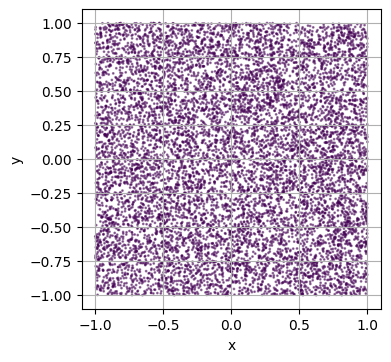

In [4]:
# import necessary libraries
from scimba_torch.integration.monte_carlo import DomainSampler


# a utility function to plot a 2D domain
def plot_2d(domain, n=10000, ax=None):
    """Plot a 2D domain using a Domain sampler."""

    # create the sampler
    sampler = DomainSampler(domain)

    # sample points
    res = sampler.sample(n)
    pts = res.x         # coordinates of the sampled points
    labels = res.labels # labels of the sampled points

    # convert to numpy for plotting
    pts = pts.detach().cpu().numpy()
    labels = labels.detach().cpu().numpy()

    # generate the ax if not provided
    if ax is None:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, xlabel='x', ylabel='y', aspect='equal')
    else:
        fig = None
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_aspect('equal')

    # plot the points
    ax.scatter(pts[:, 0], pts[:, 1], s=1, c=labels, alpha=0.5)
    ax.grid(True)

    if fig is not None:
        fig.tight_layout()
        plt.show()

    #print (n)    

square = simple_square()
plot_2d(square)


## Adding Holes to a Domain 

We can also add holes to a domain.  
A hole is a domain as well, defined with the flag `is_main_domain` set to false.

For example, let's consider a disk hole inside the domain

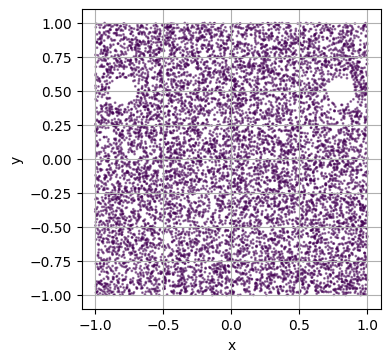

In [5]:

square = simple_square()
# create some holes
hole1 = Disk2D(center=(.8, 0.5), radius=0.1, is_main_domain=False)
hole2 = Disk2D(center=(-.8, 0.5), radius=0.1, is_main_domain=False)

# add holes to the square domain
square.add_hole(hole1)
square.add_hole(hole2)

plot_2d(square)

## Defining your own Domains with a custom SDF

In Scimba, domain are defined with a signed  function and a bounding box.
    A Domain should inherit from VolumetricDomainA Signed distance function is simply a Callable with a treshold.

Beware that a Warning will be issued during the ploting because no boundary condition was defined so far. 

It will be cured within the next cell.    

/var/folders/45/mbhz86wn2j1g87m6_9fkqby80000gn/T/ipykernel_8535/3781150211.py:10: UserWarning: The domain does not have boundary domains
  sampler = DomainSampler(domain)


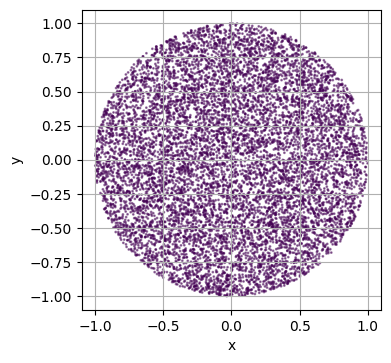

In [6]:
# import necessary libraries
from scimba_torch.domain.meshless_domain.base import VolumetricDomain
from scimba_torch.domain.sdf import SignedDistance


class CustomSDF(SignedDistance):
    """A custom SDF class that defines the signed distance function for unit 2D disk."""

    def __init__(self):
        super().__init__(
            dim=2,
            threshold=0.0,
        )

    def __call__(self, x: torch.Tensor) -> torch.Tensor:
        """Compute the signed distance function for the unit 2D disk."""
        ## WARNING, the sdf must return a tensor of shape (N, 1)
        x, y = x[:, 0], x[:, 1]
        return (torch.sqrt(x**2 + y**2) - 1.0)[:, None]  # shape (N, 1)

custom_domain = VolumetricDomain(
    domain_type="CustomUnitDisk",
    dim=2,
    sdf=CustomSDF(),
    bounds=[(-1, 1), (-1, 1)],
    is_main_domain=True
)

plot_2d(custom_domain)

## Boundary Domains

#TODO : implement default sampling with sdf when no bc domains are given.

As you can see in the last example, our custom domain does not have any boundary domains...  

In `Scimba` boundary domain (more generally called `SurfacicDomains`), are a "proper" domain (i.e. a `VolumetricDomain`) of dimension $d$, mapped to dimension $d+1$

To declare such a domain, we hence need:

- A `VolumetricDomain` (called `parametric_domain`)
- A `Mapping` (called `surface`) that embeds our `parametric_domain` into higher dimension.

Let's define the boundary of our unit disk.

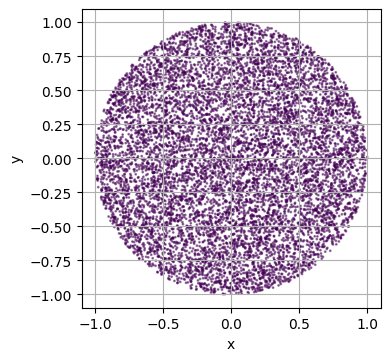

In [7]:
# import necessary libraries
from scimba_torch.domain.meshless_domain.base import SurfacicDomain
from scimba_torch.utils.mapping import Mapping

bc = SurfacicDomain(
    domain_type="CustomUnitCircle",
    parametric_domain=Segment1D((0, 2 * torch.pi)),
    surface=Mapping(
        from_dim=1,
        to_dim=2,
        map=lambda x: torch.stack([torch.cos(x[..., 0]), torch.sin(x[..., 0])], dim=-1),
    ),
)

# we then add the boundary domain to our custom domain
custom_domain.add_bc_domain(bc)

# we don't have a warning anymore :)
plot_2d(custom_domain)

Let's create a new plotting utility function to see what's happening.

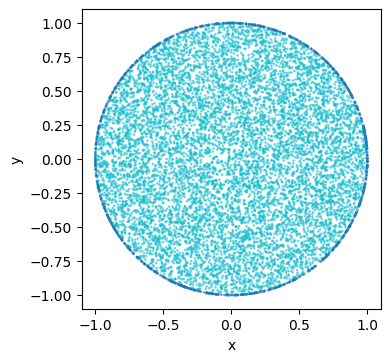

In [8]:
# a utility function to plot a 2D domain and boundary points
def plot_2d_with_bc(domain, n=10_000, n_bc=1_000, ax=None):
    """Plot a 2D domain using a Domain sampler."""

    cmap = plt.get_cmap("tab10_r")

    # create the sampler
    sampler = DomainSampler(domain)

    # sample points
    res = sampler.sample(n)
    pts = res.x  # coordinates of the sampled points
    labels = res.labels  # labels of the sampled points

    res_bc, _ = sampler.bc_sample(n_bc)
    pts_bc = res_bc.x  # coordinates of the sampled boundary points
    labels_bc = res_bc.labels  # labels of the sampled boundary points

    # convert to numpy for plotting
    pts = pts.detach().cpu().numpy()
    labels = labels.detach().cpu().numpy()
    pts_bc = pts_bc.detach().cpu().numpy()
    labels_bc = labels_bc.detach().cpu().numpy()

    # generate the ax if not provided
    if ax is None:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, xlabel="x", ylabel="y", aspect="equal")
    else:
        fig = None
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")

    # offset the labels for boundary points and find max label for color mapping
    labels_bc += labels.max() + 1
    max_label = max(labels.max(), labels_bc.max())

    # plot the points
    ax.scatter(
        pts[:, 0],
        pts[:, 1],
        s=1,
        c=labels,
        alpha=0.5,
        cmap=cmap,
        vmin=0,
        vmax=max_label,
    )

    # plot the boundary points
    ax.scatter(
        pts_bc[:, 0],
        pts_bc[:, 1],
        s=1,
        c=labels_bc,
        cmap=cmap,
        vmin=0,
        vmax=max_label,
        alpha=0.5,
    )

    if fig is not None:
        fig.tight_layout()
        plt.show()


plot_2d_with_bc(custom_domain)

**!Warning!** Be aware that their is not check or whatsoever to see it the given boundary domain is really the boundary of the given domain.

Previously, we did not get any warning because the `Square2D` domain implements `full_bc_domain`, which returns a list of `SurfacicDomain`s that represent the all boundary of a square.  
When no user-specif boundary domains are provided, it defaults to the `full_bc_domain`.

## Geometries Showcase

In [9]:
# 1D domains
segment = Segment1D(
    low_high=(-1, 1),
    is_main_domain=True
)

# 2D domains
square = Square2D(
    bounds=[(-1, 1), (0, 1)],
    is_main_domain=True
)

disk = Disk2D(
    center=(0, 0),
    radius=1,
    is_main_domain=True
)
polygon = Polygon2D(
    # vertices of the polygon, they should be provided in counter-clockwise order
    vertices=[[-1, -1], [0, -1], [.5, 0], [0, 1], [-1, 1]],
    is_main_domain=True
)

# 3D domains
cube = Cube3D(
    bounds=[(-1, 1), (0, 1), (-1, 0)],
    is_main_domain=True
)
disk3d = Disk3D(
    center=(0, 0, 0),
    radius=1,
    is_main_domain=True
)
cylinder = Cylinder3D(
    radius=1,
    length=2,
    is_main_domain=True
)
torus = Torus3D(
    center=(0, 0, 0),
    radius=1,
    tube_radius=0.2,
    is_main_domain=True
)
torus_from2d = TorusFrom2DVolume(
    base_volume=square,
    radius=2,
    is_main_domain=True
)

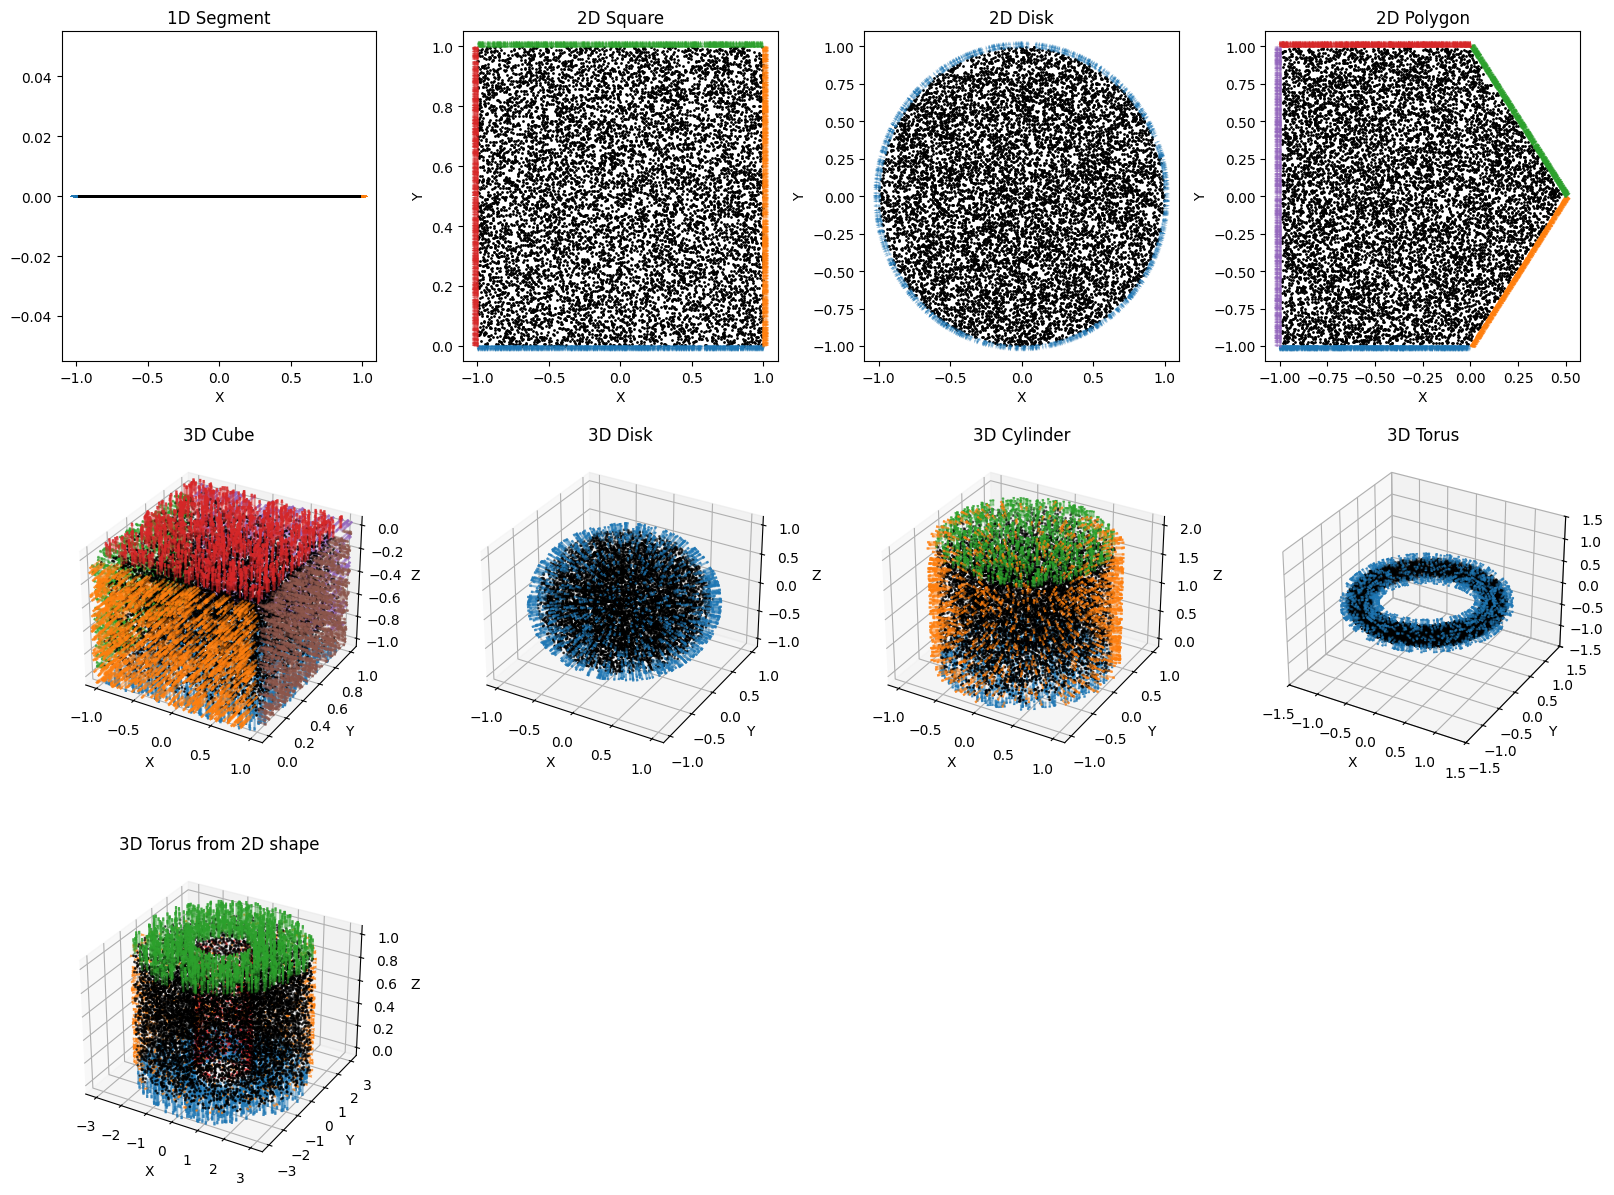

In [10]:
# import necessary libraries
from scimba_torch.integration.monte_carlo import SurfacicSampler, VolumetricSampler



# utility function to sample and plot points in a domain
def plot(dict_dom2ax, n=10_000, n_bc=1000):
    for domain, ax in dict_dom2ax.items():
        # create a sampler for the domain
        sampler = VolumetricSampler(domain)
        bc_sampler = [SurfacicSampler(bc) for bc in domain.full_bc_domain()]
        # sample N points
        pts = sampler.sample(n)
        bc_pts = [
            bc_sampler[i].sample(n_bc, compute_normals=True)
            for i in range(len(bc_sampler))
        ]
        # convert to numpy for plotting (& normalize normals)
        pts = pts.detach().numpy()
        bc_pts = [
            (bc, 0.1 * n / torch.linalg.norm(n, axis=-1, keepdims=True))
            for bc, n in bc_pts
        ]
        bc_pts = [(bc[0].detach().numpy(), bc[1].detach().numpy()) for bc in bc_pts]

        def get_pts(pts):
            if domain.dim == 1:
                return pts[:, 0], [0] * len(pts)
            elif domain.dim == 2:
                return pts[:, 0], pts[:, 1]
            elif domain.dim == 3:
                return pts[:, 0], pts[:, 1], pts[:, 2]
            else:
                raise ValueError("Domain dimension not supported for plotting.")

        ax.scatter(*get_pts(pts), color="k", s=1)  # plot the sampled points

        for i, (bc, nn) in enumerate(bc_pts):
            ax.scatter(
                *get_pts(bc), s=1, c=f"C{i}", alpha=0.2
            )  # plot the boundary points
            ax.quiver(
                *get_pts(bc), *get_pts(nn), color=f"C{i}", alpha=0.5
            )  # plot the boundary normals


fig = plt.figure(figsize=(16, 12))
dict_dom2ax = {
    segment: fig.add_subplot(3, 4, 1, xlabel="X", title="1D Segment"),
    square: fig.add_subplot(3, 4, 2, xlabel="X", ylabel="Y", title="2D Square"),
    disk: fig.add_subplot(3, 4, 3, xlabel="X", ylabel="Y", title="2D Disk"),
    polygon: fig.add_subplot(3, 4, 4, xlabel="X", ylabel="Y", title="2D Polygon"),
    cube: fig.add_subplot(
        3, 4, 5, projection="3d", xlabel="X", ylabel="Y", zlabel="Z", title="3D Cube"
    ),
    disk3d: fig.add_subplot(
        3, 4, 6, projection="3d", xlabel="X", ylabel="Y", zlabel="Z", title="3D Disk"
    ),
    cylinder: fig.add_subplot(
        3,
        4,
        7,
        projection="3d",
        xlabel="X",
        ylabel="Y",
        zlabel="Z",
        title="3D Cylinder",
    ),
    torus: fig.add_subplot(
        3,
        4,
        8,
        projection="3d",
        xlabel="X",
        ylabel="Y",
        zlabel="Z",
        xlim=(-1.5, 1.5),
        ylim=(-1.5, 1.5),
        zlim=(-1.5, 1.5),
        title="3D Torus",
    ),
    torus_from2d: fig.add_subplot(
        3,
        4,
        9,
        projection="3d",
        xlabel="X",
        ylabel="Y",
        zlabel="Z",
        title="3D Torus from 2D shape",
    ),
}

# plot the domains
plot(dict_dom2ax)
fig.tight_layout()
plt.show()

## Questions
a) on se donne plus bas un domaine cubique $[1,1]^3$ ou carré $[0,1]^2$,
et on étudie la précision de l'intégration numérique de Monte Carlo et de l'intégration numérique uniforme.

b) commencer par lire les scripts plus bas.

In [11]:
domain = cube
sampler = DomainSampler(domain)

n=1000
res = sampler.sample(n)
pts = res.x         # coordinates of the sampled points
# convert to numpy for plotting
pts = pts.detach().cpu().numpy()

print (pts)


[[-0.0792978   0.14529102 -0.73184998]
 [ 0.89883695  0.5784993  -0.07215766]
 [ 0.05387703  0.39219443 -0.5985126 ]
 ...
 [ 0.31634771  0.956177   -0.24262196]
 [-0.14058487  0.19648512 -0.57898034]
 [ 0.98309256  0.85723678 -0.42882348]]


In [12]:
import numpy as np

def function_my(x,y):
    return np.exp(x+y)

In [13]:
I=0
for i in range(0,n):
    x=pts[i][0]
    y=pts[i][1]
    I+=function_my(x,y)

I*=4
I/=n
print(I)

8.376602535651639


In [14]:
from scimba_torch.integration.mesh_based_quadrature import RectangleMethod
from scimba_torch.domain.mesh_based_domain.cuboid import Cuboid
DOMAIN_X = Cuboid(((0,1),(0,1)), is_main_domain=True) 

N=16
X_SAMPLER = RectangleMethod(DOMAIN_X)
points = X_SAMPLER.sample(N)
points=points.x
pts = points.detach().cpu().numpy()

print (pts)

[[0.   0.  ]
 [0.   0.25]
 [0.   0.5 ]
 [0.   0.75]
 [0.25 0.  ]
 [0.25 0.25]
 [0.25 0.5 ]
 [0.25 0.75]
 [0.5  0.  ]
 [0.5  0.25]
 [0.5  0.5 ]
 [0.5  0.75]
 [0.75 0.  ]
 [0.75 0.25]
 [0.75 0.5 ]
 [0.75 0.75]]


## A faire

a) Calculer la valeur analytique de $I$ qui est l'intégrale dans le domaine (cubique ou carré) de la fonction $\exp(x+y)$.

b) mettre en place un script qui permet de vérifier que la méthode de MC converge approximativement
en $O(n^{-1/2}) $ pour $n$ grand.

c)  mettre en place un scritp qui permet de vérifier que la méthode uniforme converge approximativement
en $O(n^{-1})$ pour $n$ grand.